In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

In [4]:
df = pd.read_csv('walmart_enriched.csv', parse_dates=['date'])
df.head()

,invoice_id,branch,city,category,unit_price,quantity,date,time,payment_method,rating,profit_margin,total,profit,year,month_name,day_name,hour,shift
0,1,WALM003,San Antonio,Health and beauty,74.69,7,2019-01-05,13:08:00,Ewallet,9.1,0.48,522.83,250.9584,2019,January,Saturday,13,Afternoon
1,2,WALM048,Harlingen,Electronic accessories,15.28,5,2019-03-08,10:29:00,Cash,9.6,0.48,76.40,36.6720,2019,March,Friday,10,Morning
2,3,WALM067,Haltom City,Home and lifestyle,46.33,7,2019-03-03,13:23:00,Credit card,7.4,0.33,324.31,107.0223,2019,March,Sunday,13,Afternoon
3,4,WALM064,Bedford,Health and beauty,58.22,8,2019-01-27,20:33:00,Ewallet,8.4,0.33,465.76,153.7008,2019,January,Sunday,20,Evening
4,5,WALM013,Irving,Sports and travel,86.31,7,2019-02-08,10:37:00,Ewallet,5.3,0.48,604.17,290.0016,2019,February,Friday,10,Morning


In [5]:
BLUE, GREY, RED = '#2a6fdb', '#b8c2cc', '#d64545'
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

In [6]:
def money(x, pos):
    return f'{x/1000:.0f}K'

In [7]:
b = df.groupby('branch').agg(revenue=('total', 'sum'), rating=('rating', 'mean'))
top25 = b['revenue'].rank(ascending=False) <= 25

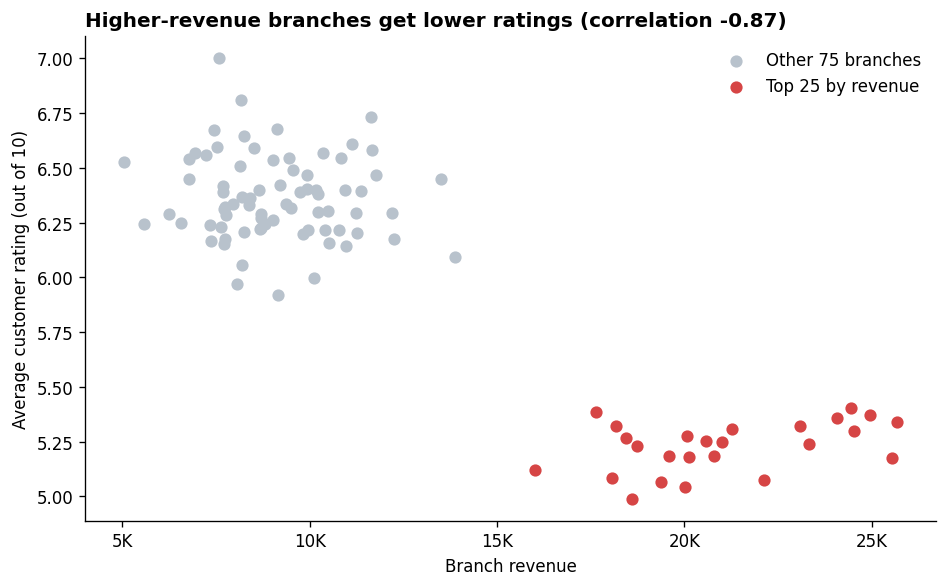

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(b.loc[~top25, 'revenue'], b.loc[~top25, 'rating'], color=GREY, s=40, label='Other 75 branches')
ax.scatter(b.loc[top25, 'revenue'], b.loc[top25, 'rating'], color=RED, s=40, label='Top 25 by revenue')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.set_xlabel('Branch revenue')
ax.set_ylabel('Average customer rating (out of 10)')
corr = b['revenue'].corr(b['rating'])
ax.set_title(f'Higher-revenue branches get lower ratings (correlation {corr:.2f})', loc='left', fontweight='bold')
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig('1_revenue_vs_rating.png'); plt.show()

In [9]:
full = df[df['year'].between(2020, 2023)]
m = full.groupby(full['date'].dt.month)['total'].sum() / 4
labels = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
colors = [RED if i >= 11 else (BLUE if i >= 8 else GREY) for i in m.index]

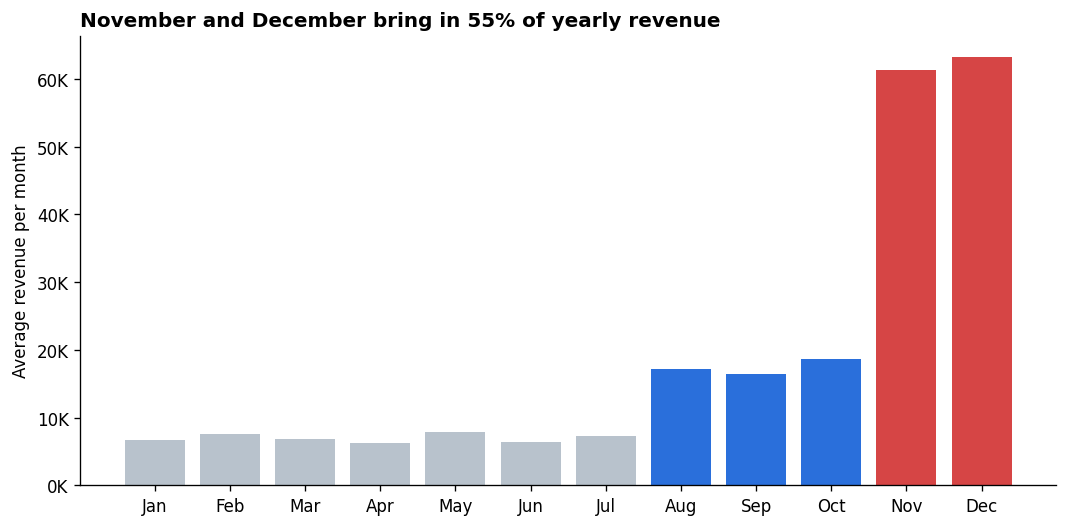

In [10]:

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(labels, m.values, color=colors)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.set_ylabel('Average revenue per month')
share = 100 * m.loc[[11, 12]].sum() / m.sum()
ax.set_title(f'November and December bring in {share:.0f}% of yearly revenue', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('2_seasonality.png'); plt.show()

In [11]:
h = df.groupby('hour').size()
colors = [RED if 15 <= x <= 20 else GREY for x in h.index]

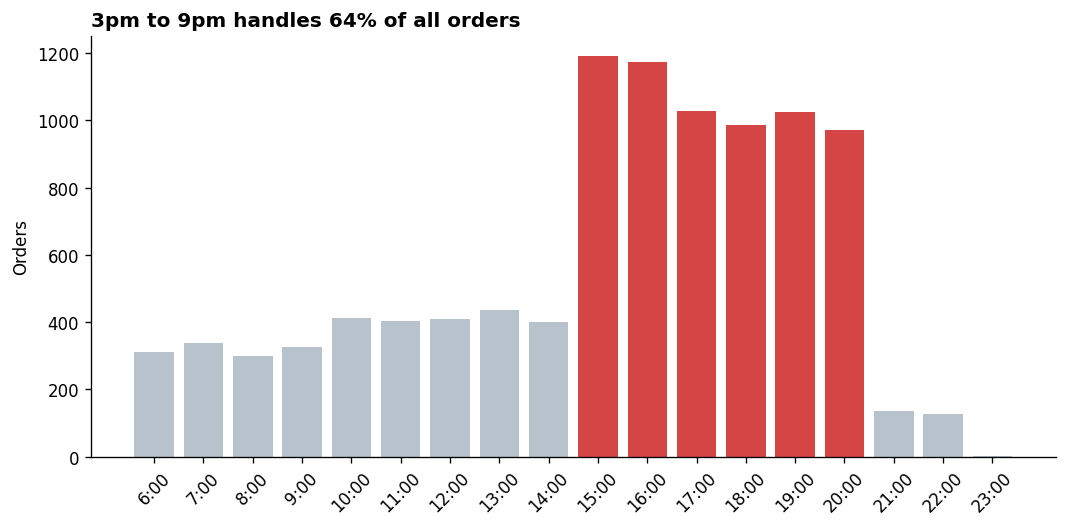

In [12]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(h.index, h.values, color=colors)
ax.set_xticks(h.index)
ax.set_xticklabels([f'{x}:00' for x in h.index], rotation=45)
ax.set_ylabel('Orders')
peak = 100 * h.loc[15:20].sum() / h.sum()
ax.set_title(f'3pm to 9pm handles {peak:.0f}% of all orders', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('3_orders_by_hour.png'); plt.show()

In [13]:
p = df.groupby('profit_margin').agg(orders=('total', 'size'), profit=('profit', 'sum'))
p = p.loc[[0.33, 0.48]]

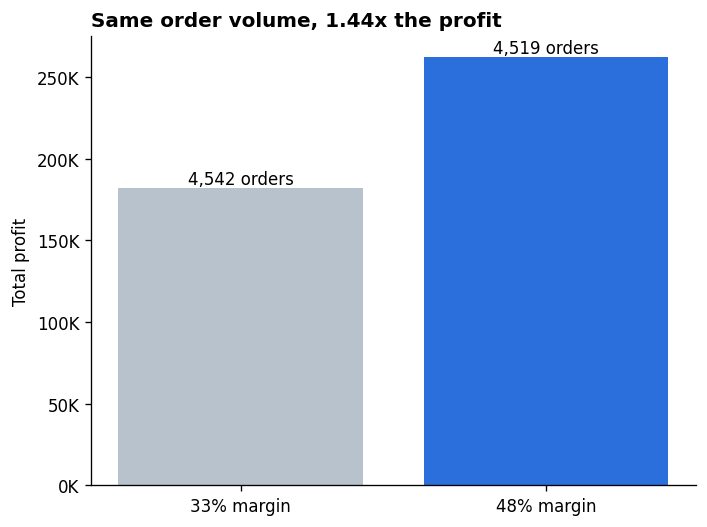

In [14]:
fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(['33% margin', '48% margin'], p['profit'], color=[GREY, BLUE])
for bar, n in zip(bars, p['orders']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f'{n:,} orders',
            ha='center', va='bottom')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(money))
ax.set_ylabel('Total profit')
ratio = p.loc[0.48, 'profit'] / p.loc[0.33, 'profit']
ax.set_title(f'Same order volume, {ratio:.2f}x the profit', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('4_margin_profit.png'); plt.show()

In [15]:
r = df.groupby('payment_method')['rating'].mean().sort_values()
colors = [BLUE if x == 'Ewallet' else GREY for x in r.index]

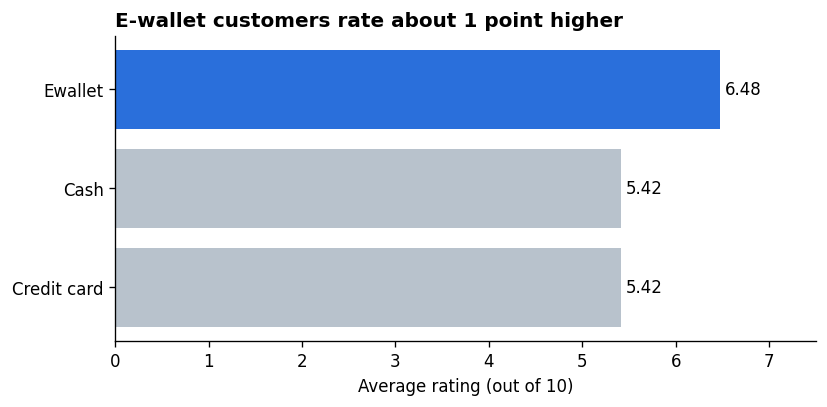

In [16]:

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(r.index, r.values, color=colors)
for i, v in enumerate(r.values):
    ax.text(v + 0.05, i, f'{v:.2f}', va='center')
ax.set_xlim(0, 7.5)
ax.set_xlabel('Average rating (out of 10)')
ax.set_title('E-wallet customers rate about 1 point higher', loc='left', fontweight='bold')
plt.tight_layout(); plt.savefig('5_rating_by_payment.png'); plt.show()

In [17]:
from google.colab import files
for f in ['1_revenue_vs_rating.png', '2_seasonality.png', '3_orders_by_hour.png',
          '4_margin_profit.png', '5_rating_by_payment.png']:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>